# Análise exploratória e validação preditiva — UI-PRMD / Deep Squat

**Universidade Presbiteriana Mackenzie** · Inteligência Artificial, 7ºJ (SI — Noite) · Prof. Dr. Leandro Zerbinatti  
**Projeto:** Análise preditiva com IA para exercícios de musculação  
**Integrantes:** Bruna França Martinez — RA 10420225 — 10420225@mackenzista.com.br; Graziely de Oliveira Severo — RA 10425431 — 10425431@mackenzista.com.br; Matheus Fernandes dos Santos — RA 10420439 — 10420439@mackenzista.com.br.

**Finalidade real da entrega:** análise exploratória, visualização de um canal angular ao longo de diferentes repetições e estimação experimental dos *escores gerados pelo GMM* do UI-PRMD, usando regressão Ridge. **Não** há neste notebook extração com MediaPipe, aferição de fadiga, diagnóstico de lesões ou feedback postural em tempo real.

**Reprodução:** garanta que a pasta `dataset/` exista ao lado do notebook (devem existir os seis CSVs, `Prepare_Data_for_NN.m` e `Prepare_Labels_for_NN.m`); instale as dependências do `requirements.txt`; execute todas as células. PNGs e métricas são salvos em `resultados/`.

**Histórico das alterações:** 14/09/2026 — Matheus Fernandes dos Santos — estrutura e exploração inicial; 15/11/2026 — validação por participante, regularização, interpretação angular, integridade dos dados e resultados reprodutíveis.

## 1. Bibliotecas e configuração

Ajustes de hiperparâmetros são escolhidos **somente no conjunto de treinamento**. O teste separado por participante fica isolado até a avaliação final.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = Path("dataset")
OUT_DIR = Path("resultados")
OUT_DIR.mkdir(parents=True, exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
sns.set_theme(style="whitegrid")
print("Pasta de dados:", DATA_DIR.resolve())

Pasta de dados: C:\Users\Mathe\OneDrive\Desktop\projetos\projetos-faculdade\projeto-ia-mackenzie\dataset


## 2. Carregamento, dimensões e integridade

Os arquivos `Data_*.csv` contêm **117 canais angulares × 90 execuções** nas linhas (organizadas em blocos por execução) e 240 posições temporais nas colunas. Cada `Autoencoder_Output_*.csv` contém 90 execuções × (4 canais latentes × 240 frames). As linhas zeradas/duplicadas em `Data_*.csv` podem resultar de canais invariantes: não devem ser removidas sem preservar o mapeamento de 117 linhas para uma execução.

In [2]:
def carregar_dados(base=DATA_DIR):
    nomes = (
        "Data_Correct.csv", "Data_Incorrect.csv",
        "Labels_Correct.csv", "Labels_Incorrect.csv",
        "Autoencoder_Output_Correct.csv", "Autoencoder_Output_Incorrect.csv"
    )
    faltantes = [nome for nome in nomes if not (base / nome).is_file()]
    if faltantes:
        raise FileNotFoundError(
            f"Não encontrei {faltantes} em {base.resolve()}. "
            "Extraia dataset(1).zip para a pasta dataset/."
        )
    return {nome: pd.read_csv(base / nome, header=None) for nome in nomes}

arquivos = carregar_dados()
for nome, tabela in arquivos.items():
    valores = tabela.to_numpy(dtype=float)
    print(f"{nome:39s} | dimensões: {str(tabela.shape):13s} | "
          f"nulos: {int(tabela.isna().sum().sum()):5d} | infinitos: {int(np.isinf(valores).sum()):5d}")
    if not np.isfinite(valores).all():
        raise ValueError(f"Há valores não finitos no arquivo {nome}.")

esperado = {"Data_Correct.csv": (10530, 240), "Data_Incorrect.csv": (10530, 240),
            "Labels_Correct.csv": (90, 1), "Labels_Incorrect.csv": (90, 1),
            "Autoencoder_Output_Correct.csv": (90, 960),
            "Autoencoder_Output_Incorrect.csv": (90, 960)}
for nome, dimensoes in esperado.items():
    if arquivos[nome].shape != dimensoes:
        raise ValueError(f"Formato inesperado em {nome}: {arquivos[nome].shape} != {dimensoes}")

for classe in ("Correct", "Incorrect"):
    tab = arquivos[f"Data_{classe}.csv"]
    print(f"Data_{classe}: linhas totalmente zeradas = "
          f"{int((tab == 0).all(axis=1).sum())}; "
          f"linhas duplicadas exatas = {int(tab.duplicated().sum())}")

Data_Correct.csv                        | dimensões: (10530, 240)  | nulos:     0 | infinitos:     0
Data_Incorrect.csv                      | dimensões: (10530, 240)  | nulos:     0 | infinitos:     0
Labels_Correct.csv                      | dimensões: (90, 1)       | nulos:     0 | infinitos:     0
Labels_Incorrect.csv                    | dimensões: (90, 1)       | nulos:     0 | infinitos:     0
Autoencoder_Output_Correct.csv          | dimensões: (90, 960)     | nulos:     0 | infinitos:     0
Autoencoder_Output_Incorrect.csv        | dimensões: (90, 960)     | nulos:     0 | infinitos:     0
Data_Correct: linhas totalmente zeradas = 360; linhas duplicadas exatas = 809
Data_Incorrect: linhas totalmente zeradas = 360; linhas duplicadas exatas = 809


## 3. Estatística descritiva dos escores GMM

Esses escores são **pseudo-rótulos computados por GMM**, e não avaliações de um profissional de educação física. No script `Prepare_Labels_for_NN.m`, o GMM é ajustado à base de execuções corretas e os escores são escalonados; essa construção dos rótulos usa dados de vários participantes. A validação do regressor abaixo, portanto, **não elimina essa dependência global dos rótulos**.

           count      mean       std      min       25%       50%       75%      max
classe                                                                              
Correto     90.0  0.944383  0.011675  0.90288  0.934957  0.946600  0.954040  0.96092
Incorreto   90.0  0.860708  0.067721  0.53019  0.829375  0.880215  0.907975  0.94531


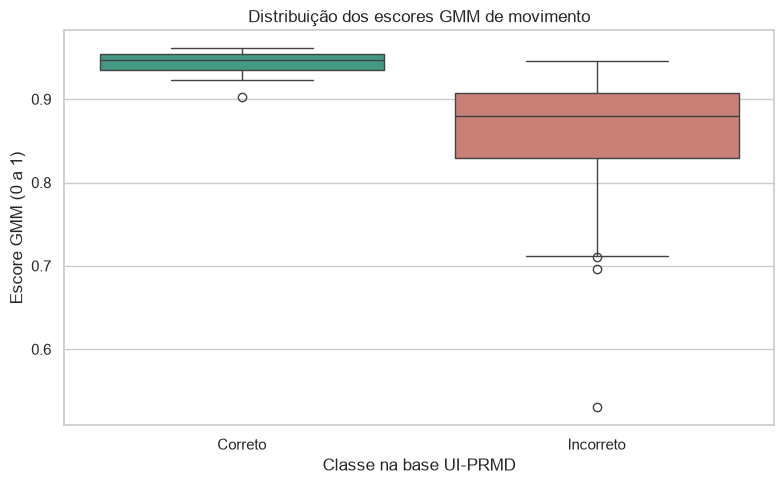

In [3]:
labels_corretos = arquivos["Labels_Correct.csv"].iloc[:, 0].to_numpy(dtype=float)
labels_incorretos = arquivos["Labels_Incorrect.csv"].iloc[:, 0].to_numpy(dtype=float)
y = np.concatenate([labels_corretos, labels_incorretos])
classe = np.array(["Correto"] * 90 + ["Incorreto"] * 90)
df_scores = pd.DataFrame({"classe": classe, "quality_score": y})
estatisticas = df_scores.groupby("classe")["quality_score"].describe()
print(estatisticas.to_string())
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_scores, x="classe", y="quality_score", order=["Correto", "Incorreto"],
            palette=["#36a78b", "#d6776a"], hue="classe", dodge=False, legend=False, ax=ax)
ax.set(title="Distribuição dos escores GMM de movimento", xlabel="Classe na base UI-PRMD", ylabel="Escore GMM (0 a 1)")
fig.tight_layout()
fig.savefig(OUT_DIR / "figura_1_boxplot_escores.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Trajetórias temporais — mesmo canal angular em execuções diferentes

No script `Prepare_Data_for_NN.m`, `Correct_Xm = [Correct_Aligned{1}'; ...]`; logo, cada sequência ocupa **117 linhas consecutivas**. A linha `i * 117 + canal` recupera o **mesmo canal** na execução `i`. Como os valores foram centrados/normalizados, o eixo vertical não representa graus absolutos. Não se atribui identidade anatômica ao canal 0 sem metadados específicos.

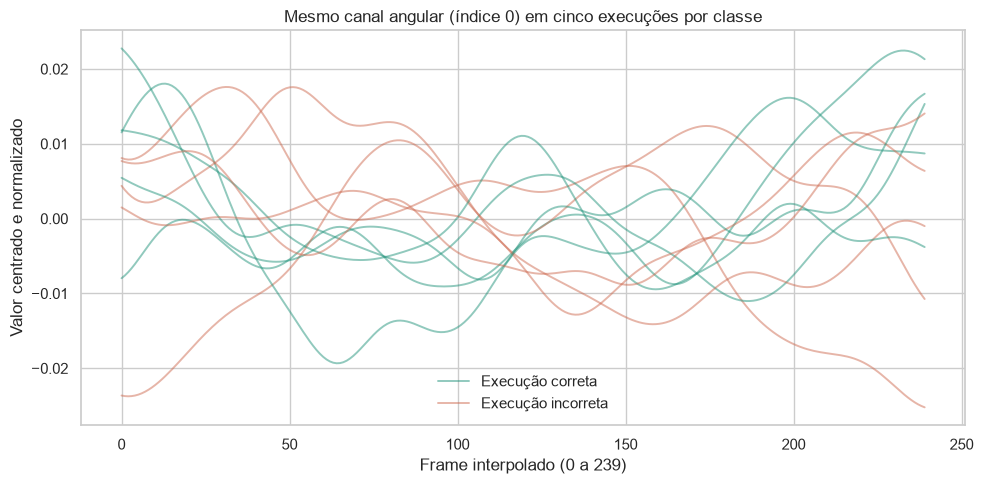

In [4]:
data_corr = arquivos["Data_Correct.csv"].to_numpy(dtype=float)
data_inc = arquivos["Data_Incorrect.csv"].to_numpy(dtype=float)
canal = 0
repeticoes = [0, 1, 2, 3, 4]
frames = np.arange(240)
fig, ax = plt.subplots(figsize=(10, 5))
for i in repeticoes:
    linha = i * 117 + canal
    ax.plot(frames, data_corr[linha], color="#198f76", alpha=.48, lw=1.4,
            label="Execução correta" if i == 0 else None)
    ax.plot(frames, data_inc[linha], color="#cc654a", alpha=.48, lw=1.4,
            label="Execução incorreta" if i == 0 else None)
ax.set(title="Mesmo canal angular (índice 0) em cinco execuções por classe",
       xlabel="Frame interpolado (0 a 239)", ylabel="Valor centrado e normalizado")
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "figura_2_trajetorias_mesmo_canal.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Identificação dos participantes e extração de características

Os IDs abaixo são **reconstruídos da ordem original de leitura e seleção de sequências** em `Prepare_Data_for_NN.m`: 100 execuções iniciais em ordem por pessoa, 10 por pessoa; 90 sequências mantidas por classe nos índices MATLAB 1-based especificados no script. Os mesmos índices foram aplicados aos conjuntos correto e incorreto. Essa derivação é válida **somente enquanto os CSVs preservarem a ordem do pipeline fornecido**.

As 960 posições latentes são reorganizadas em `240 frames × 4 canais`. Reduzimos sua dimensionalidade a 24 medidas **definidas a priori** (média, desvio-padrão, mínimo, máximo, percentil 25 e percentil 75 de cada um dos quatro canais), sem usar o alvo. O escalonamento das características é ajustado exclusivamente no treino, via `Pipeline`.

In [5]:
# Índices das 90 execuções selecionadas, extraídos literalmente de Prepare_Data_for_NN.m
indices_matlab = np.r_[2:11, 12:21, 22:31, 32:41, 42:51,
                       51:61, 62:64, 65:71, 72:81, 82:85, 86:91, 91:101]
assert len(indices_matlab) == 90 and len(np.unique(indices_matlab)) == 90
ids_por_classe = (indices_matlab - 1) // 10 + 1  # 1 a 10
grupo = np.concatenate([ids_por_classe, ids_por_classe])
X_latente = np.concatenate([
    arquivos["Autoencoder_Output_Correct.csv"].to_numpy(dtype=float),
    arquivos["Autoencoder_Output_Incorrect.csv"].to_numpy(dtype=float)
], axis=0)
assert X_latente.shape == (180, 960) and len(y) == len(grupo) == 180

# MATLAB: quatro canais intercalados a cada frame; ref. Prepare_Labels_for_NN.m
movimentos = X_latente.reshape(-1, 240, 4)
X = np.hstack([
    movimentos.mean(axis=1),
    movimentos.std(axis=1),
    movimentos.min(axis=1),
    movimentos.max(axis=1),
    np.percentile(movimentos, 25, axis=1),
    np.percentile(movimentos, 75, axis=1),
])
assert X.shape == (180, 24)
print(f"Entrada bruta: {X_latente.shape}; descritores para regressão: {X.shape}")
print("Execuções por participante (por classe):", pd.Series(ids_por_classe).value_counts().sort_index().to_dict())

Entrada bruta: (180, 960); descritores para regressão: (180, 24)
Execuções por participante (por classe): {1: 9, 2: 9, 3: 9, 4: 9, 5: 9, 6: 10, 7: 8, 8: 9, 9: 8, 10: 10}


## 6. Treino/teste por participante, seleção por validação cruzada e baseline

- Separação: `GroupShuffleSplit(test_size=0.2, random_state=42)`, sem participantes compartilhados. 
- Dentro do treino: `GroupKFold(n_splits=4)` otimiza `alpha` da regressão Ridge pelo **MSE de validação**, sem observar o teste.
- Comparação: `DummyRegressor(strategy="mean")` ajustado no mesmo treino.
- Teste: usado **uma única vez**, após a seleção de `alpha`; reportam-se MAE, MSE e R². Amostra de dez participantes e apenas dois no teste implica alta incerteza.

In [6]:
split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
idx_treino, idx_teste = next(split.split(X, y, groups=grupo))
participantes_treino = sorted(set(grupo[idx_treino].tolist()))
participantes_teste = sorted(set(grupo[idx_teste].tolist()))
assert set(participantes_treino).isdisjoint(participantes_teste)
print("Participantes de treino:", participantes_treino)
print("Participantes de teste:", participantes_teste)
print("Amostras de treino:", len(idx_treino), "| teste:", len(idx_teste))

pipeline = Pipeline([
    ("padronizacao", StandardScaler()),
    ("regressao", Ridge())
])
cv = GroupKFold(n_splits=4)
busca = GridSearchCV(
    estimator=pipeline,
    param_grid={"regressao__alpha": [0.1, 1.0, 10.0, 100.0, 1000.0]},
    scoring="neg_mean_squared_error", cv=cv, n_jobs=1, refit=True
)
busca.fit(X[idx_treino], y[idx_treino], groups=grupo[idx_treino])
print("MSE médio na validação cruzada (quanto menor, melhor):")
for alpha, valor in zip(busca.cv_results_["param_regressao__alpha"],
                        -busca.cv_results_["mean_test_score"]):
    print(f" alpha={float(alpha):7.1f} -> {float(valor):.6f}")
print("Melhor alpha (selecionado no treino):", busca.best_params_["regressao__alpha"])

referencia = DummyRegressor(strategy="mean")
referencia.fit(X[idx_treino], y[idx_treino])
pred_ref = referencia.predict(X[idx_teste])
pred_modelo = busca.best_estimator_.predict(X[idx_teste])

def avaliar(nome, reais, previstos):
    return {"modelo": nome,
            "mae": float(mean_absolute_error(reais, previstos)),
            "mse": float(mean_squared_error(reais, previstos)),
            "r2": float(r2_score(reais, previstos))}

metricas = pd.DataFrame([
    avaliar("Baseline (média do treino)", y[idx_teste], pred_ref),
    avaliar("Ridge (24 descritores)", y[idx_teste], pred_modelo),
]).set_index("modelo")
print("\nRESULTADOS EM TESTE (PARTICIPANTES NÃO VISTOS PELO REGRESSOR)")
print(metricas.to_string(float_format=lambda v: f"{v:.6f}"))
print("ATENÇÃO: a etapa original de construção dos rótulos GMM utilizou o conjunto de dados público completo.")

Participantes de treino: [1, 3, 4, 5, 6, 7, 8, 10]
Participantes de teste: [2, 9]
Amostras de treino: 146 | teste: 34
MSE médio na validação cruzada (quanto menor, melhor):
 alpha=    0.1 -> 0.000908
 alpha=    1.0 -> 0.000960
 alpha=   10.0 -> 0.001038
 alpha=  100.0 -> 0.001182
 alpha= 1000.0 -> 0.001734
Melhor alpha (selecionado no treino): 0.1

RESULTADOS EM TESTE (PARTICIPANTES NÃO VISTOS PELO REGRESSOR)
                                mae      mse        r2
modelo                                                
Baseline (média do treino) 0.072981 0.011154 -0.122487
Ridge (24 descritores)     0.032383 0.002247  0.773872
ATENÇÃO: a etapa original de construção dos rótulos GMM utilizou o conjunto de dados público completo.


## 7. Gráficos de teste e registro dos resultados

A Figura 3 usa **exclusivamente** as 34 execuções do conjunto de teste (participantes 2 e 9 nesta divisão), não as observações de treinamento. Salva-se um JSON com as métricas e o protocolo para reproducibilidade.

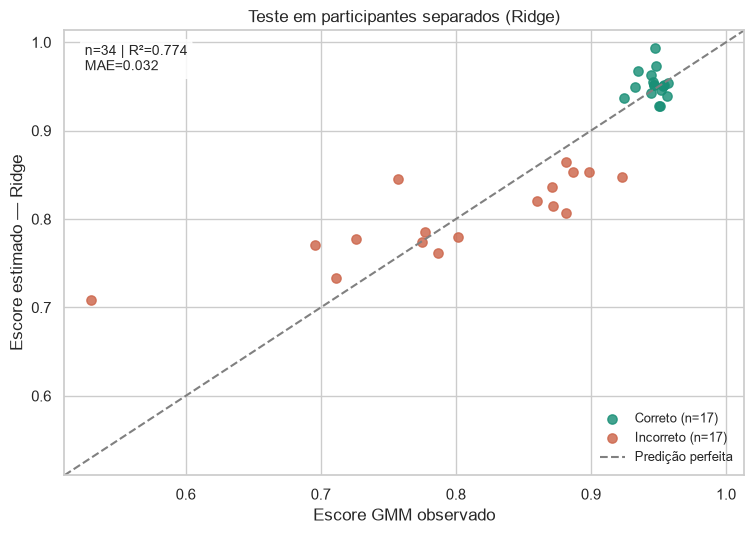

Arquivos gerados em C:\Users\Mathe\OneDrive\Desktop\projetos\projetos-faculdade\projeto-ia-mackenzie\resultados
Conclusão: o modelo aproxima escores GMM no benchmark, sem comprovação de aplicação clínica ou generalização externa.


In [7]:
fig, ax = plt.subplots(figsize=(7.7, 5.5))
classes_teste = classe[idx_teste]
for classe_alvo, cor in [("Correto", "#198f76"), ("Incorreto", "#cc654a")]:
    filtro = classes_teste == classe_alvo
    ax.scatter(y[idx_teste][filtro], pred_modelo[filtro], alpha=.82, s=45,
               label=f"{classe_alvo} (n={int(filtro.sum())})", color=cor)
lim_inf = min(float(y[idx_teste].min()), float(pred_modelo.min())) - .02
lim_sup = max(float(y[idx_teste].max()), float(pred_modelo.max())) + .02
ax.plot([lim_inf, lim_sup], [lim_inf, lim_sup], "--", color="gray", lw=1.5, label="Predição perfeita")
ax.set(xlim=(lim_inf, lim_sup), ylim=(lim_inf, lim_sup),
       xlabel="Escore GMM observado", ylabel="Escore estimado — Ridge",
       title="Teste em participantes separados (Ridge)")
ax.text(.03, .97, f"n={len(idx_teste)} | R²={metricas.loc['Ridge (24 descritores)', 'r2']:.3f}\n"
        f"MAE={metricas.loc['Ridge (24 descritores)', 'mae']:.3f}",
        transform=ax.transAxes, ha="left", va="top", fontsize=10,
        bbox={"boxstyle": "round", "facecolor": "white", "alpha": .85})
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(OUT_DIR / "figura_3_regressao_teste_participantes.png", dpi=200, bbox_inches="tight")
plt.show()

resumo = {
    "dataset": "UI-PRMD / Deep Squat (benchmark público)",
    "n_total": int(len(y)),
    "n_treino": int(len(idx_treino)), "n_teste": int(len(idx_teste)),
    "participantes_treino": participantes_treino,
    "participantes_teste": participantes_teste,
    "n_caracteristicas_originais": 960, "n_descritores": 24,
    "algoritmo": "StandardScaler + Ridge",
    "criterio_selecao": "GroupKFold (4 folds) no treino; MSE",
    "melhor_alpha": float(busca.best_params_["regressao__alpha"]),
    "cv_mse_medio_melhor_alpha": float(-busca.best_score_),
    "resultado_baseline_teste": metricas.loc["Baseline (média do treino)"].to_dict(),
    "resultado_ridge_teste": metricas.loc["Ridge (24 descritores)"].to_dict(),
    "restricoes": [
        "Labels GMM computados a partir do conjunto público completo (dependência global entre os rótulos)",
        "Poucos participantes; divisão única de teste não valida uso clínico",
        "Dados originais do grupo e processamento MediaPipe ausentes",
        "Escore GMM não mede diretamente fadiga, risco de lesão ou correção biomecânica"
    ]
}
(OUT_DIR / "metricas_validacao.json").write_text(json.dumps(resumo, indent=2, ensure_ascii=False), encoding="utf-8")
print("Arquivos gerados em", OUT_DIR.resolve())
print("Conclusão: o modelo aproxima escores GMM no benchmark, sem comprovação de aplicação clínica ou generalização externa.")